In [1]:
import json
from pathlib import Path

import numpy as np

from experiments._common import H4_FCIDUMP_PATH, H4_FCI_ENERGY

from qcmps import (
    FCIDumpLoader,
    GlobalQCMPS, Ansatz, HFPreset,
    Logger,
    TwoSiteOptimizer,
    SO4Gate, StarLayerType, BrickWallLayerType,
    Observable,
)
from qcmps.layers import LUBondConnectedLayerType

In [76]:
RUN_A = 0
RUN_B = 6

output_test = Path.cwd() / "output_test"
output_dir = Path.cwd() / "output_expand"
output_dir.mkdir(exist_ok=True)

name = f"h4_connected_star_{RUN_A}_{RUN_B}_expanded2"
checkpoint_path = output_dir / f"{name}_check.json"
previous_checkpoint_path = output_test / f"h4_connected_star_{RUN_A}_{RUN_B}_check.json"
logging_path = output_dir / f"{name}.log"
value_path = output_dir / f"{name}.csv"

logger = Logger(logging_path, value_file=value_path, continue_logging=False)

In [77]:
loader = FCIDumpLoader(H4_FCIDUMP_PATH)
loader.interleave_spin_orbitals()

hamiltonian_operator = loader.hamiltonian
nuclear_repulsion = loader.nuclear_repulsion
hf_occupancy = loader.hf_occupancy()

num_phys_qubits = loader.n_spin_orbitals
num_bond_qubits = 2
num_qubits = num_phys_qubits + num_bond_qubits

physical_qubits = list(range(num_phys_qubits))
bond_qubits = list(range(num_phys_qubits, num_qubits))
input_physical_qubits = list(range(num_bond_qubits, num_qubits))

In [78]:
star_a_layer = StarLayerType(SO4Gate, center_qubit=0, target_qubits=[1])
bond_connector_layer = LUBondConnectedLayerType(SO4Gate, bond_qubits=[1, 2])
star_b_layer = StarLayerType(SO4Gate, center_qubit=0, target_qubits=[2])

qcmps = GlobalQCMPS(
    num_phys_qubits,
    num_bond_qubits,
    [star_a_layer, bond_connector_layer, star_b_layer],
)

ansatz = Ansatz(num_qubits)
hf_preset = HFPreset(num_phys_qubits, hf_occupancy)

ansatz.add_component(hf_preset, input_physical_qubits)
ansatz.add_component(qcmps, list(range(num_qubits)))

ansatz.load_checkpoint(previous_checkpoint_path)

In [79]:
hamiltonian = Observable(
    hamiltonian_operator,
    physical_qubits,
    constant=nuclear_repulsion,
    label="Total energy",
)
particle_number = Observable.particle_number(physical_qubits)
alpha_number = Observable.alpha_particle_number(physical_qubits)
beta_number = Observable.beta_particle_number(physical_qubits)

In [82]:
initial_energy = hamiltonian(ansatz)

logger.log(f"Initial total energy: {initial_energy:.12f}")
logger.log(f"Initial energy variance: {hamiltonian.var(ansatz):.12f}")
logger.log(f"Initial particle number: {particle_number(ansatz):.12f}")
logger.log(f"Initial particle number variance: {particle_number.var(ansatz):.12f}")
logger.log_value(hamiltonian.label, initial_energy, 1)

Initial total energy: -2.228801618666
Initial energy variance: 0.050359490899
Initial particle number: 3.999996757492
Initial particle number variance: 0.000008232192


In [81]:
qcmps.insert_layers(2, [StarLayerType(SO4Gate)])
ansatz.rebuild()

In [83]:
new_layers = qcmps.layer_parameter_groups(2)

logger.log("Starting new layer optimization...")
connector_optimizer = TwoSiteOptimizer(
    logger,
    log_every_n_steps=None,
    max_sweeps=10,
    local_maxiter=10,
    tolerance=1e-8,
)
connector_result = connector_optimizer.optimize(
    ansatz,
    hamiltonian,
    qcmps,
    active_parameters=new_layers,
)

Starting new layer optimization...
[Optimizer] Sweep 1/10 started.
[Optimizer] [Sweep 1 Site pair 1-2] Total energy: -2.228802427459
[Optimizer] [Sweep 1 Site pair 2-3] Total energy: -2.228802705504
[Optimizer] [Sweep 1 Site pair 3-4] Total energy: -2.228802717282
[Optimizer] [Sweep 1 Site pair 4-5] Total energy: -2.228803231126
[Optimizer] [Sweep 1 Site pair 5-6] Total energy: -2.228806072793
[Optimizer] [Sweep 1 Site pair 6-7] Total energy: -2.228806369016
[Optimizer] [Sweep 1 Site pair 7-8] Total energy: -2.228806712864
[Optimizer] [Sweep 1 Site pair 6-7] Total energy: -2.228806713402
[Optimizer] [Sweep 1 Site pair 5-6] Total energy: -2.228807312336
[Optimizer] [Sweep 1 Site pair 4-5] Total energy: -2.228807328144
[Optimizer] [Sweep 1 Site pair 3-4] Total energy: -2.228807329898
[Optimizer] [Sweep 1 Site pair 2-3] Total energy: -2.228807572499
[Optimizer] [Sweep 1] Total energy: -2.228807572499, Relative change: 2.671e-06
[Optimizer] Sweep 2/10 started.
[Optimizer] [Sweep 2 Site pai

KeyboardInterrupt: 

In [56]:
connector_energy = hamiltonian(ansatz)
logger.log(f"Energy after connector optimization: {connector_energy:.12f}")
logger.log(f"Connector energy improvement: {initial_energy - connector_energy:.12e}")

Energy after connector optimization: -2.228815250107
Connector energy improvement: 1.106532828130e-04


In [44]:
logger.log("Starting full Two site optimization...")
full_optimizer = TwoSiteOptimizer(
    logger,
    log_every_n_steps=None,
    max_sweeps=2,
    local_maxiter=10,
    tolerance=1e-8,
)
full_result = full_optimizer.optimize(ansatz, hamiltonian, qcmps)

Starting full Two site optimization...
[Optimizer] Sweep 1/2 started.
[Optimizer] [Sweep 1 Site pair 1-2] Total energy: -2.228807817502
[Optimizer] [Sweep 1 Site pair 2-3] Total energy: -2.228807818215
[Optimizer] [Sweep 1 Site pair 3-4] Total energy: -2.228807818572
[Optimizer] [Sweep 1 Site pair 4-5] Total energy: -2.228807819957
[Optimizer] [Sweep 1 Site pair 5-6] Total energy: -2.228807832352
[Optimizer] [Sweep 1 Site pair 6-7] Total energy: -2.228807836110
[Optimizer] [Sweep 1 Site pair 7-8] Total energy: -2.228807837402
[Optimizer] [Sweep 1 Site pair 6-7] Total energy: -2.228807944089
[Optimizer] [Sweep 1 Site pair 5-6] Total energy: -2.228807946329
[Optimizer] [Sweep 1 Site pair 4-5] Total energy: -2.228807947455
[Optimizer] [Sweep 1 Site pair 3-4] Total energy: -2.228807948314
[Optimizer] [Sweep 1 Site pair 2-3] Total energy: -2.228807949832
[Optimizer] [Sweep 1] Total energy: -2.228807949832, Relative change: 5.996e-08
[Optimizer] Sweep 2/2 started.
[Optimizer] [Sweep 2 Site p

In [57]:
final_energy = hamiltonian(ansatz)

logger.log(f"Final total energy: {final_energy:.12f}")
logger.log(f"Final energy variance: {hamiltonian.var(ansatz):.12f}")
logger.log(f"Particle number: {particle_number(ansatz):.12f}")
logger.log(f"Particle number variance: {particle_number.var(ansatz):.12f}")
logger.log(f"Alpha particle number: {alpha_number(ansatz):.12f}")
logger.log(f"Beta particle number: {beta_number(ansatz):.12f}")
logger.log(f"Absolute FCI error: {abs(final_energy - H4_FCI_ENERGY):.12e}")

Final total energy: -2.228815250107
Final energy variance: 0.050378901923
Particle number: 4.000000465813
Particle number variance: 0.000129029599
Alpha particle number: 1.999961931915
Beta particle number: 2.000038533898
Absolute FCI error: 2.714682325897e-02


In [58]:
ansatz.save_checkpoint(checkpoint_path)

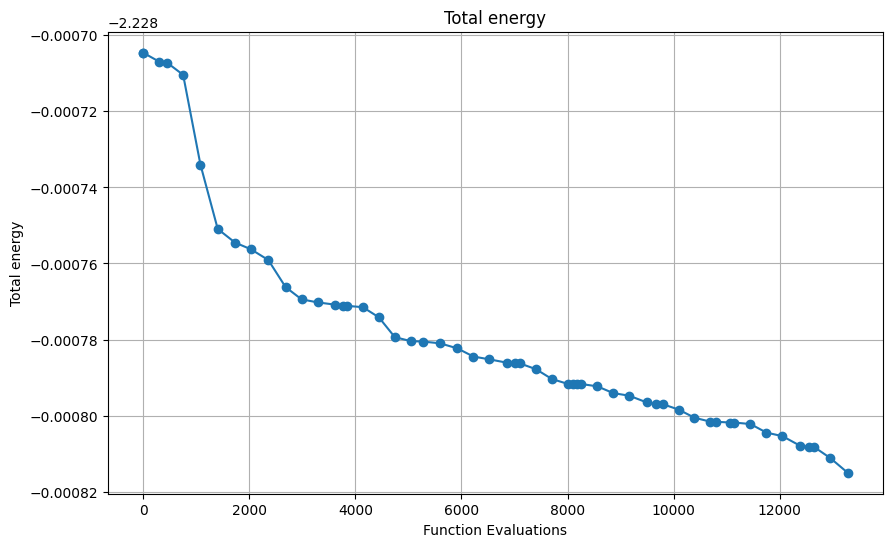

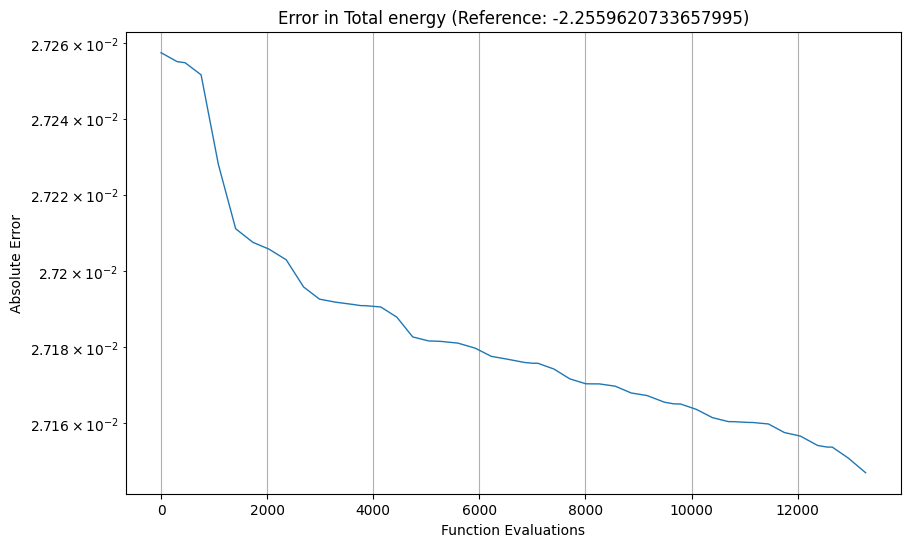

In [59]:
logger.plot_values(hamiltonian.label)
logger.plot_error(hamiltonian.label, H4_FCI_ENERGY, log_scale=True)